# Lecture 11: every figure in the slides

These cells are the code that produced the mlp training figures in the deck, with each file write replaced by an inline plot. The notebook runs independently of the slide repository.

In [1]:
# Colab opens this notebook on its own, so fetch the data files that sit
# beside it in the course repository. Running locally, this does nothing.
from pathlib import Path as _Path
import urllib.request as _req
_RAW = 'https://raw.githubusercontent.com/ZhuoranYang/sds265-fall26/main/demos/11-mlp-training/'
for _name in ['SklearnDigits.csv']:
    if not _Path(_name).exists():
        _req.urlretrieve(_RAW + _name, _name)

In [2]:
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The course palette and figure sizes, copied from slides/figures/sds265_style.py
BLUE, BLUE_BRIGHT, RED, GREEN = '#00356B', '#286DC0', '#7A3E47', '#5B7864'
INK, MUTED, RULE, BLUE_PALE = '#202A35', '#66727E', '#D8E0E8', '#F2F6FA'
BLUE_FILL, RED_FILL, GREEN_FILL = '#8C9FB1', '#B0846F', '#9AAE96'
MORANDI_BLUE, MORANDI_CLAY, MORANDI_SAGE = '#8C9FB1', '#B0846F', '#9AAE96'
MORANDI_MAUVE, MORANDI_SAND, MORANDI_STONE = '#A98FA0', '#C7B392', '#8A8F8A'
MORANDI = [MORANDI_BLUE, MORANDI_CLAY, MORANDI_SAGE, MORANDI_MAUVE, MORANDI_SAND, MORANDI_STONE]
MORANDI_EDGE = {MORANDI_BLUE: '#5C7186', MORANDI_CLAY: '#835747', MORANDI_SAGE: '#6B8067',
                MORANDI_MAUVE: '#7C6373', MORANDI_SAND: '#9A8763', MORANDI_STONE: '#5F645F'}
CYCLE = MORANDI
TEXTWIDTH, TEXTHEIGHT = 5.63, 3.09
FULL, FULL_TALL, FULL_SHORT = (TEXTWIDTH, 2.0), (TEXTWIDTH, 2.35), (TEXTWIDTH, 1.7)
HALF, HALF_TALL = (2.70, 2.05), (2.70, 2.45)

def use_course_style():
    mpl.rcParams.update({'figure.dpi': 130, 'font.size': 9, 'axes.titlecolor': BLUE,
                         'axes.edgecolor': MUTED, 'axes.linewidth': .7,
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'xtick.color': MUTED, 'ytick.color': MUTED,
                         'legend.frameon': False, 'lines.linewidth': 1.8,
                         'axes.prop_cycle': mpl.cycler(color=CYCLE)})

def save(fig, *paths):     # the deck writes files; the notebook shows the plot
    plt.show()
    return Path(paths[0]) if paths else Path('figure.pdf')

use_course_style()
# The deck scripts derive output paths from OUT and NOTES. Nothing is written
# here, so both point at the working directory and the notebook runs anywhere.
OUT = Path('.')
NOTES = Path('.')

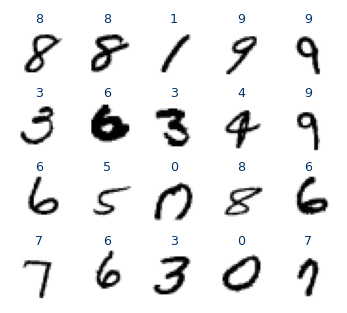

In [3]:
from __future__ import annotations

import gzip
import struct
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from torch import nn



DATA = Path(".")
SEED = 26511
MNIST_URL = "https://ossci-datasets.s3.amazonaws.com/mnist/"


# --- data --------------------------------------------------------------------

def load_mnist(folder):
    """MNIST as float arrays in [0, 1] with integer labels, cached in ``folder``."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    splits = {}
    for split, prefix in (("train", "train"), ("test", "t10k")):
        arrays = []
        for kind in ("images-idx3-ubyte", "labels-idx1-ubyte"):
            name = f"{prefix}-{kind}.gz"
            path = folder / name
            if not path.exists():
                urllib.request.urlretrieve(MNIST_URL + name, path)
            with gzip.open(path, "rb") as handle:
                _, count = struct.unpack(">II", handle.read(8))
                if "images" in kind:
                    rows, cols = struct.unpack(">II", handle.read(8))
                    data = np.frombuffer(handle.read(), np.uint8).reshape(count, rows * cols)
                else:
                    data = np.frombuffer(handle.read(), np.uint8)
            arrays.append(data)
        splits[split] = (arrays[0].astype(np.float32) / 255, arrays[1].astype(np.int64))
    return splits


def load_digits_tensors():
    """The 8x8 scikit-learn digits, standardized, as tensors."""
    digits = pd.read_csv(Path("SklearnDigits.csv"))
    y = torch.tensor(digits["target"].to_numpy(), dtype=torch.long)
    X = torch.tensor(digits.drop(columns="target").to_numpy(), dtype=torch.float32)
    X = (X - X.mean(0)) / (X.std(0) + 1e-6)
    return X, y


def two_moons(n=180, seed=26512):
    """Two interleaved half-circles, the classroom demo's data."""
    rng = np.random.default_rng(seed)
    angle = rng.uniform(0, np.pi, n)
    upper = np.column_stack([np.cos(angle), np.sin(angle)]) + rng.normal(0, 0.10, (n, 2))
    lower = np.column_stack([1 - np.cos(angle), 0.5 - np.sin(angle)]) + rng.normal(0, 0.10, (n, 2))
    return np.vstack([upper, lower]), np.r_[np.zeros(n), np.ones(n)]


# --- the data and the model --------------------------------------------------

def mnist_examples() -> None:
    """Twenty training images with their labels."""
    X, y = load_mnist(Path("mnist"))["train"]
    pick = np.random.default_rng(SEED).choice(len(X), 20, replace=False)
    fig, axes = plt.subplots(4, 5, figsize=(2.6, 2.35))
    for ax, i in zip(axes.ravel(), pick):
        ax.imshow(X[i].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(str(y[i]), fontsize=7, color=BLUE, pad=1.5)
        ax.axis("off")
    fig.subplots_adjust(left=0.01, right=0.99, top=0.91, bottom=0.01, wspace=0.08, hspace=0.4)
    save(fig, OUT / "mnist-examples.pdf")


def digits_hidden_weights() -> None:
    """First-layer weights of a sixteen-unit MLP fitted to MNIST, drawn as images."""
    splits = load_mnist(Path("mnist"))
    X, y = (torch.tensor(a) for a in splits["train"])
    X_test, y_test = (torch.tensor(a) for a in splits["test"])
    torch.manual_seed(SEED)
    model = nn.Sequential(nn.Linear(784, 16), nn.ReLU(), nn.Linear(16, 10))
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
    loss_fn = nn.CrossEntropyLoss()
    generator = torch.Generator().manual_seed(SEED)
    for _ in range(2):
        order = torch.randperm(len(X), generator=generator)
        for start in range(0, len(X), 128):
            index = order[start:start + 128]
            loss = loss_fn(model(X[index]), y[index])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    with torch.no_grad():
        accuracy = (model(X_test).argmax(1) == y_test).float().mean().item()
    weights = model[0].weight.detach().numpy()
    fig, axes = plt.subplots(2, 4, figsize=(5.63, 2.45))
    for j, ax in enumerate(axes.ravel()):
        scale = np.abs(weights[j]).max()
        ax.imshow(weights[j].reshape(28, 28), cmap="RdBu_r", vmin=-scale, vmax=scale)
        ax.set_title(f"Unit {j + 1}", fontsize=8, color=BLUE, pad=2)
        ax.axis("off")
    fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.01, wspace=0.08, hspace=0.3)
    save(fig, OUT / "digits-hidden-weights.pdf")
    print(f"  sixteen-unit MLP, two epochs: test accuracy {accuracy:.3f}")


def training_snapshots() -> None:
    """The decision rule of a width-8 tanh network at four moments of training."""
    X, y = two_moons()
    width, rate, snapshots = 8, 3.0, (0, 20, 100, 800)
    local = np.random.default_rng(26512 + width)
    W1 = local.normal(0, 0.65, (2, width))
    b1 = np.zeros(width)
    W2 = local.normal(0, 0.50, (width, 1))
    b2 = np.zeros(1)

    def sigmoid(v):
        return 1 / (1 + np.exp(-np.clip(v, -30, 30)))

    xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 220), np.linspace(-1.2, 1.6, 220))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    fig, axes = plt.subplots(1, 4, figsize=(5.63, 1.9), sharex=True, sharey=True)
    panel = 0
    for t in range(snapshots[-1] + 1):
        if t in snapshots:
            ax = axes[panel]
            panel += 1
            prob = sigmoid((np.tanh(grid @ W1 + b1) @ W2 + b2).ravel()).reshape(xx.shape)
            ax.contourf(xx, yy, prob, levels=[0, 0.5, 1], colors=["#DCE8F2", "#F4DEE0"])
            ax.contour(xx, yy, prob, levels=[0.5], colors=[GREEN], linewidths=1.4)
            ax.scatter(X[y == 0, 0], X[y == 0, 1], s=5, color=BLUE)
            ax.scatter(X[y == 1, 0], X[y == 1, 1], s=5, color=RED)
            ax.set(title=f"Update {t}", xlabel="$x_1$")
        if t == snapshots[-1]:
            break
        H = np.tanh(X @ W1 + b1)
        p = sigmoid((H @ W2 + b2).ravel())
        dlogit = (p - y)[:, None] / len(y)
        dW2, db2 = H.T @ dlogit, dlogit.sum(0)
        dZ = (dlogit @ W2.T) * (1 - H ** 2)
        dW1, db1 = X.T @ dZ, dZ.sum(0)
        W1 -= rate * dW1
        b1 -= rate * db1
        W2 -= rate * dW2
        b2 -= rate * db2
    axes[0].set_ylabel("$x_2$")
    fig.tight_layout(w_pad=0.4)
    save(fig, OUT / "demo-training-snapshots.pdf")


def digits_width_accuracy() -> None:
    """Training and validation accuracy against hidden width, on real digits."""
    from sklearn.datasets import load_digits
    from sklearn.model_selection import train_test_split
    from sklearn.neural_network import MLPClassifier
    from sklearn.preprocessing import StandardScaler

    X, y = load_digits(return_X_y=True)
    X_train, X_valid, y_train, y_valid = train_test_split(
        X, y, test_size=.30, random_state=SEED, stratify=y)
    scaler = StandardScaler().fit(X_train)
    X_train, X_valid = scaler.transform(X_train), scaler.transform(X_valid)

    widths = [4, 8, 16, 32, 64]
    train_acc, valid_acc = [], []
    for w in widths:
        net = MLPClassifier(hidden_layer_sizes=(w,), max_iter=3000,
                            random_state=SEED, alpha=1e-4)
        net.fit(X_train, y_train)
        train_acc.append(net.score(X_train, y_train))
        valid_acc.append(net.score(X_valid, y_valid))

    fig, ax = plt.subplots(figsize=(5.63, 3.55))
    ax.plot(widths, train_acc, "o-", color=MORANDI_BLUE, lw=2, ms=7,
            markeredgecolor=MORANDI_EDGE[MORANDI_BLUE], label="training")
    ax.plot(widths, valid_acc, "o-", color=MORANDI_CLAY, lw=2, ms=7,
            markeredgecolor=MORANDI_EDGE[MORANDI_CLAY], label="validation")
    ax.set_xscale("log", base=2)
    ax.set_xticks(widths)
    ax.set_xticklabels([str(w) for w in widths])
    ax.set_xlabel("hidden width", fontsize=12)
    ax.set_ylabel("accuracy", fontsize=12)
    ax.tick_params(labelsize=11)
    ax.set_ylim(min(valid_acc) - .04, 1.015)
    ax.legend(frameon=False, loc="lower right", fontsize=11)
    ax.set_title("Width buys capacity, and the gap it opens is overfitting",
                 color=BLUE, fontsize=12.5)
    ax.annotate(f"{train_acc[-1] - valid_acc[-1]:.3f} gap",
                xy=(widths[-1], (train_acc[-1] + valid_acc[-1]) / 2), xytext=(-6, 0),
                textcoords="offset points", ha="right", va="center", fontsize=10, color=MUTED)
    fig.tight_layout()
    save(fig, OUT / "digits-width-accuracy.pdf")
    print("  train:", [round(a, 4) for a in train_acc])
    print("  valid:", [round(a, 4) for a in valid_acc])


# --- stabilization -------------------------------------------------------------

def gradient_products() -> None:
    """What repeated multiplication by a local slope does to a gradient."""
    depth = np.arange(0, 41)
    fig, ax = plt.subplots(figsize=FULL)
    for slope, colour, note in ((1.2, RED, "explodes"), (1.0, GREEN, "stays put"), (0.8, BLUE, "vanishes")):
        factor = slope ** depth
        ax.plot(depth, factor, color=colour, label=f"local slope {slope}")
        ax.annotate(f"{factor[-1]:.0e}  {note}", (depth[-1], factor[-1]),
                    textcoords="offset points", xytext=(-4, 6 if slope != 0.8 else -14),
                    ha="right", fontsize=8, color=colour)
    ax.axhline(1, color=MUTED, lw=.7, ls=":")
    ax.set(yscale="log", xlabel="number of layers the gradient passes through",
           ylabel="factor applied to the gradient",
           title="Backprop multiplies one factor per layer, so depth compounds it")
    ax.legend(loc="center left", fontsize=8)
    save(fig, OUT / "gradient-products.pdf", OUT / "gradient-products.svg")
    print("  factors at depth 40:", {s: round(float(s ** 40), 6) for s in (0.8, 1.0, 1.2)})


def layer_gradient_norms() -> None:
    """Weight-gradient norm per hidden layer, sigmoid against ReLU, same init."""
    X, y = load_digits_tensors()

    def hidden_gradients(activation):
        torch.manual_seed(0)
        layers = []
        for _ in range(9):
            linear = nn.Linear(64, 64)
            nn.init.xavier_normal_(linear.weight)
            nn.init.zeros_(linear.bias)
            layers += [linear, activation()]
        layers.append(nn.Linear(64, 10))
        network = nn.Sequential(*layers)
        nn.CrossEntropyLoss()(network(X[:128]), y[:128]).backward()
        return np.array([m.weight.grad.norm().item() for m in layers[:-1] if isinstance(m, nn.Linear)])

    sigmoid, relu = hidden_gradients(nn.Sigmoid), hidden_gradients(nn.ReLU)
    layer = np.arange(1, 10)
    fig, ax = plt.subplots(figsize=FULL)
    ax.plot(layer, sigmoid, "o-", color=MORANDI_EDGE[MORANDI_CLAY], ms=4, label="sigmoid network")
    ax.plot(layer, relu, "o-", color=BLUE, ms=4, label="ReLU network")
    ax.set(yscale="log", xlabel="hidden layer, from input to output",
           ylabel="weight-gradient norm", xticks=layer,
           title="Gradient scale varies across a deep computation graph")
    ax.legend(loc="upper left", fontsize=8)
    save(fig, OUT / "layer-gradient-norms.pdf")
    print(f"  sigmoid: layer 9 over layer 1 = {sigmoid[-1] / sigmoid[0]:.1e}; "
          f"ReLU: {relu[-1] / relu[0]:.2f}")


def residual_block() -> None:
    """A plain block beside a residual block, drawn large enough to read."""
    fig, axes = plt.subplots(1, 2, figsize=(5.63, 2.25), sharey=True)

    def block(ax, residual: bool, title: str):
        ax.axis("off")
        ax.set(xlim=(0, 1), ylim=(0, 1))
        width, height, x0 = 0.42, 0.135, 0.29
        layers = [("weight layer", 0.30), ("activation", 0.48), ("weight layer", 0.66)]
        for label, y in layers:
            ax.add_patch(FancyBboxPatch((x0, y - height / 2), width, height,
                                        boxstyle="round,pad=0.012,rounding_size=0.03",
                                        facecolor="#F2F6FA", edgecolor=BLUE, lw=1.1))
            ax.text(x0 + width / 2, y, label, ha="center", va="center", fontsize=8.5)
        ax.annotate("", xy=(0.5, 0.30 - height / 2), xytext=(0.5, 0.10),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.1))
        ax.annotate("", xy=(0.5, 0.48 - height / 2), xytext=(0.5, 0.30 + height / 2),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.1))
        ax.annotate("", xy=(0.5, 0.66 - height / 2), xytext=(0.5, 0.48 + height / 2),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.1))
        ax.text(0.5, 0.055, "$x$", ha="center", va="center", fontsize=11, color=INK)

        if residual:
            ax.add_patch(FancyArrowPatch((0.5, 0.66 + height / 2), (0.5, 0.845),
                                         arrowstyle="-|>", mutation_scale=10, color=MUTED, lw=1.1))
            ax.add_patch(plt.Circle((0.5, 0.88), 0.035, facecolor="white",
                                    edgecolor=MORANDI_EDGE[MORANDI_CLAY], lw=1.4, zorder=4))
            ax.text(0.5, 0.88, "$+$", ha="center", va="center", fontsize=10, color=RED, zorder=5)
            ax.plot([0.5, 0.87], [0.10, 0.10], color=MORANDI_EDGE[MORANDI_CLAY], lw=1.4)
            ax.plot([0.87, 0.87], [0.10, 0.88], color=MORANDI_EDGE[MORANDI_CLAY], lw=1.4)
            ax.add_patch(FancyArrowPatch((0.87, 0.88), (0.545, 0.88), arrowstyle="-|>",
                                         mutation_scale=10, color=RED, lw=1.4))
            ax.text(0.90, 0.50, "identity", rotation=90, ha="center", va="center",
                    fontsize=8.5, color=RED)
            ax.annotate("", xy=(0.5, 0.985), xytext=(0.5, 0.925),
                        arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.1))
            ax.text(0.30, 0.955, "$x+F(x)$", ha="center", va="center", fontsize=10, color=INK)
            ax.text(0.14, 0.48, "$F(x)$", ha="center", va="center", fontsize=10, color=BLUE)
        else:
            ax.add_patch(FancyArrowPatch((0.5, 0.66 + height / 2), (0.5, 0.985),
                                         arrowstyle="-|>", mutation_scale=10, color=MUTED, lw=1.1))
            ax.text(0.30, 0.955, "$F(x)$", ha="center", va="center", fontsize=10, color=INK)
        ax.set_title(title, fontsize=9.5, color=BLUE)

    block(axes[0], False, "plain block: learn the whole map")
    block(axes[1], True, "residual block: learn a correction")
    fig.tight_layout(w_pad=0.6)
    save(fig, OUT / "residual-block.pdf", OUT / "residual-block.svg")


def lr_schedules() -> None:
    """The shapes of the schedules named on the slide."""
    total = 1000
    step = np.arange(total)
    base = 1.0
    warm = 100

    constant = np.full(total, base)
    step_decay = base * 0.5 ** (step // 300)
    cosine = base * 0.5 * (1 + np.cos(np.pi * step / total))
    warm_cosine = np.where(step < warm, base * step / warm,
                           base * 0.5 * (1 + np.cos(np.pi * (step - warm) / (total - warm))))

    fig, ax = plt.subplots(figsize=FULL)
    for values, colour, label in ((constant, MUTED, "constant"),
                                  (step_decay, GREEN, "step decay"),
                                  (cosine, BLUE, "cosine decay"),
                                  (warm_cosine, RED, "warmup, then cosine")):
        ax.plot(step, values, color=colour, label=label)
    ax.axvline(warm, color=MORANDI_EDGE[MORANDI_CLAY], lw=.7, ls=":")
    ax.text(warm + 12, 1.03, "end of warmup", fontsize=7.5, color=RED)
    ax.set(xlabel="training step", ylabel="learning rate (relative)",
           ylim=(0, 1.12), title="Four schedules for the same budget")
    ax.legend(loc="lower left", fontsize=8, ncol=2)
    save(fig, OUT / "lr-schedules.pdf", OUT / "lr-schedules.svg")


class Deep(nn.Module):
    """Ten hidden tanh layers, optionally residual, with a settable init scale."""

    def __init__(self, residual: bool, gain: float | None, width: int = 64, depth: int = 10):
        super().__init__()
        self.first = nn.Linear(64, width)
        self.blocks = nn.ModuleList([nn.Linear(width, width) for _ in range(depth)])
        self.head = nn.Linear(width, 10)
        self.residual = residual
        if gain is not None:
            for layer in [self.first, *self.blocks, self.head]:
                nn.init.normal_(layer.weight, std=gain)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        h = torch.tanh(self.first(x))
        for block in self.blocks:
            out = torch.tanh(block(h))
            h = h + out if self.residual else out
        return self.head(h)


def run_deep(X_all, y_all, residual, gain, clip=None, schedule=False, steps=400, lr=0.05, seed=0):
    """Train one Deep network on random minibatches; return the smoothed loss curve."""
    torch.manual_seed(seed)
    model = Deep(residual, gain)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = []
    for t in range(steps):
        if schedule:
            factor = min(1.0, (t + 1) / 40) * 0.5 * (1 + np.cos(np.pi * t / steps))
            for group in optimizer.param_groups:
                group["lr"] = lr * max(factor, 1e-3)
        index = torch.randint(0, len(X_all), (128,))
        loss = loss_fn(model(X_all[index]), y_all[index])
        optimizer.zero_grad()
        loss.backward()
        if clip is not None:
            nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        history.append(float(loss.detach()))
    return np.convolve(history, np.ones(20) / 20, mode="valid")


def stabilization_comparison() -> None:
    """Train the same network four ways and compare the training curves."""
    X_all, y_all = load_digits_tensors()

    # 1/sqrt(fan_in) = 1/8 for a width-64 layer: the scale that keeps the
    # forward signal from dying or saturating.
    runs = {
        "plain, std $0.02$ (too small)": run_deep(X_all, y_all, False, 0.02),
        "plain, std $0.125=1/\\sqrt{64}$": run_deep(X_all, y_all, False, 0.125),
        "plain, std $0.6$ (too large)": run_deep(X_all, y_all, False, 0.6),
        "residual, std $0.125$": run_deep(X_all, y_all, True, 0.125),
    }
    fig, axes = plt.subplots(1, 2, figsize=FULL)
    for (label, curve), colour in zip(runs.items(), [MUTED, RED, BLUE, GREEN]):
        axes[0].plot(curve, color=colour, label=label)
    axes[0].axhline(np.log(10), color=MUTED, lw=.7, ls=":")
    axes[0].text(6, np.log(10) * 1.03, "chance", fontsize=7.5, color=MUTED)
    axes[0].set(xlabel="step", ylabel="training loss", title="ten hidden layers: the initial scale")
    axes[0].legend(fontsize=7)

    # At lr = 1.0 the plain run is unstable, which is where the two
    # optimizer-side devices can be told apart.
    variants = {
        "no clipping, constant rate": run_deep(X_all, y_all, False, 0.125, lr=1.0),
        "clipping at $1.0$": run_deep(X_all, y_all, False, 0.125, clip=1.0, lr=1.0),
        "warmup and cosine": run_deep(X_all, y_all, False, 0.125, schedule=True, lr=1.0),
    }
    for (label, curve), colour in zip(variants.items(), [RED, BLUE, GREEN]):
        axes[1].plot(curve, color=colour, label=label)
    axes[1].set(xlabel="step", yscale="log", title="the same net at twenty times the rate")
    axes[1].legend(fontsize=7)
    fig.tight_layout(w_pad=0.7)
    save(fig, OUT / "stabilization-comparison.pdf", OUT / "stabilization-comparison.svg")
    for name, curve in {**runs, **variants}.items():
        print(f"  {name:32s} final smoothed loss {curve[-1]:.3f}")


def gradient_clipping() -> None:
    """What clipping does to one vector, and how often it fires in practice."""
    # --- left: the rule, drawn ---------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=FULL, gridspec_kw={"width_ratios": [1, 1.35]})
    ax = axes[0]
    c = 1.0
    circle = plt.Circle((0, 0), c, facecolor="#F2F6FA", edgecolor=MORANDI_EDGE[MORANDI_BLUE], lw=1.2, zorder=1)
    ax.add_patch(circle)
    long_g = np.array([2.05, 1.45])
    short_g = np.array([0.45, 0.62])
    clipped = long_g * c / np.linalg.norm(long_g)
    ax.add_patch(FancyArrowPatch((0, 0), tuple(long_g), arrowstyle="-|>", mutation_scale=11,
                                 color=RED, lw=1.6, zorder=3))
    ax.add_patch(FancyArrowPatch((0, 0), tuple(clipped), arrowstyle="-|>", mutation_scale=11,
                                 color=GREEN, lw=2.2, zorder=4))
    ax.add_patch(FancyArrowPatch((0, 0), tuple(short_g), arrowstyle="-|>", mutation_scale=11,
                                 color=MUTED, lw=1.6, zorder=3))
    ax.plot(*zip(clipped, long_g), color=MORANDI_EDGE[MORANDI_CLAY], ls=":", lw=1.0, zorder=2)
    ax.text(long_g[0] + 0.08, long_g[1] + 0.10, "$g$: too long", color=RED, fontsize=8.5)
    ax.text(clipped[0] + 0.12, clipped[1] - 0.02, "clipped", color=GREEN, fontsize=8.5,
            va="center")
    ax.text(short_g[0] - 0.10, short_g[1] + 0.22, "a short $g$ is untouched", color=MUTED,
            fontsize=8, ha="center")
    ax.text(-1.35, -1.30, "ball of radius $c$", color=BLUE, fontsize=8.5, ha="left")
    ax.set(xlim=(-1.55, 3.3), ylim=(-1.7, 2.3), aspect="equal", xticks=[], yticks=[],
           title="direction kept, length capped")
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)

    # --- right: how often it fires on a real run ---------------------------
    X_all, y_all = load_digits_tensors()
    torch.manual_seed(11)
    model = nn.Sequential(nn.Linear(64, 128), nn.Tanh(), nn.Linear(128, 128), nn.Tanh(),
                          nn.Linear(128, 10))
    optimizer = torch.optim.SGD(model.parameters(), lr=0.5)
    loss_fn = nn.CrossEntropyLoss()
    norms = []
    for _ in range(600):
        index = torch.randint(0, len(X_all), (32,))
        loss = loss_fn(model(X_all[index]), y_all[index])
        optimizer.zero_grad()
        loss.backward()
        norms.append(float(torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters()))))
        optimizer.step()
    norms = np.array(norms)
    threshold = float(np.quantile(norms, 0.90))
    ax = axes[1]
    ax.plot(norms, color=MORANDI_EDGE[MORANDI_BLUE], lw=.8)
    ax.axhline(threshold, color=MORANDI_EDGE[MORANDI_CLAY], lw=1.2, ls="--")
    ax.text(len(norms) * 0.98, threshold * 0.72, f"clip at $c={threshold:.1f}$", color=RED,
            fontsize=8, ha="right", va="top")
    ax.set(yscale="log", xlabel="training step", ylabel="gradient norm",
           title=f"{(norms > threshold).mean():.0%} of steps exceed this $c$")
    fig.tight_layout(w_pad=0.7)
    save(fig, OUT / "gradient-clipping.pdf", OUT / "gradient-clipping.svg")
    print(f"  gradient norms: median {np.median(norms):.2f}, max {norms.max():.2f}, "
          f"ratio {norms.max()/np.median(norms):.1f}x")


def dropout_figure() -> None:
    """The same small network before and after dropping units."""
    rng = np.random.default_rng(4)
    layers = [4, 5, 5, 3]
    positions = []
    for k, count in enumerate(layers):
        ys = np.linspace(0, 1, count)
        positions.append([(k / (len(layers) - 1), y) for y in ys])

    keep = [[True] * len(layer) for layer in positions]
    for k in (1, 2):
        drop = rng.choice(len(positions[k]), 2, replace=False)
        for j in drop:
            keep[k][j] = False

    fig, axes = plt.subplots(1, 2, figsize=(5.63, 2.15))
    for ax, use_dropout, title in ((axes[0], False, "all units present"),
                                   (axes[1], True, "one dropout mask")):
        for k in range(len(positions) - 1):
            for a, (xa, ya) in enumerate(positions[k]):
                for b, (xb, yb) in enumerate(positions[k + 1]):
                    live = (not use_dropout) or (keep[k][a] and keep[k + 1][b])
                    ax.plot([xa, xb], [ya, yb], color=MUTED if live else "#E6EBF0",
                            lw=.5, alpha=.9 if live else .6, zorder=1)
        for k, layer in enumerate(positions):
            for j, (x, y) in enumerate(layer):
                live = (not use_dropout) or keep[k][j]
                ax.scatter(x, y, s=110, zorder=3,
                           facecolor="#F2F6FA" if live else "white",
                           edgecolor=MORANDI_EDGE[MORANDI_BLUE] if live else RED,
                           linewidth=1.2)
                if not live:
                    ax.plot([x - .022, x + .022], [y - .045, y + .045], color=MORANDI_EDGE[MORANDI_CLAY], lw=1.2, zorder=4)
                    ax.plot([x - .022, x + .022], [y + .045, y - .045], color=MORANDI_EDGE[MORANDI_CLAY], lw=1.2, zorder=4)
        ax.set(xlim=(-0.1, 1.1), ylim=(-0.2, 1.2), xticks=[], yticks=[], title=title)
        ax.axis("off")
    fig.suptitle("Dropout trains a different thinned network on every minibatch",
                 fontsize=9.5, color=BLUE)
    fig.tight_layout(w_pad=0.5)
    save(fig, OUT / "dropout-mlp.pdf", OUT / "dropout-mlp.svg")




# Calls preserved from the script's __main__ block.
mnist_examples()

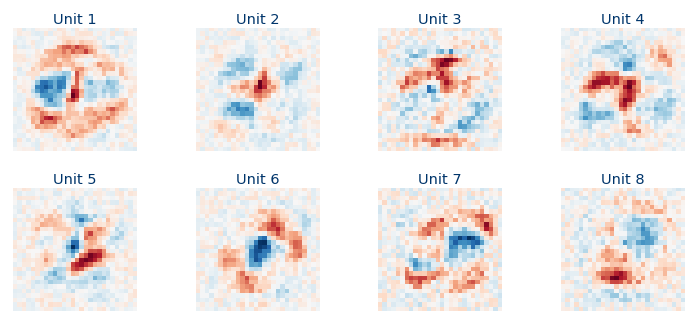

  sixteen-unit MLP, two epochs: test accuracy 0.919


In [4]:
digits_hidden_weights()

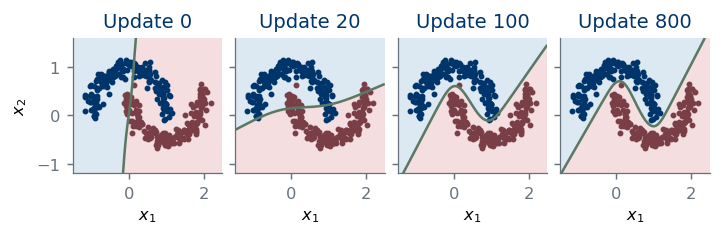

In [5]:
training_snapshots()

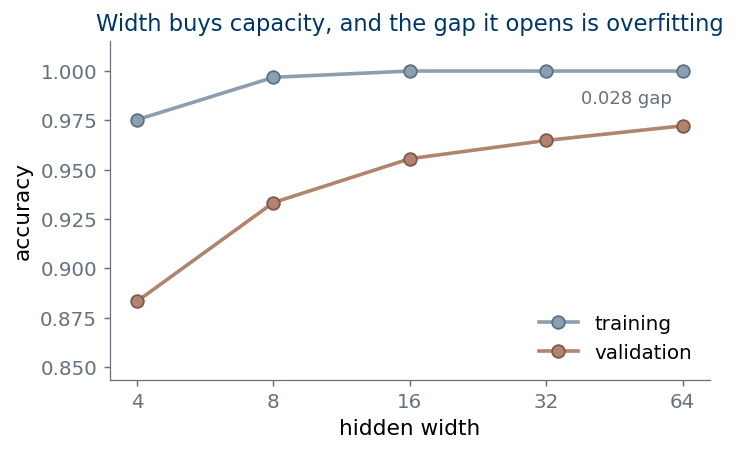

  train: [0.9753, 0.9968, 1.0, 1.0, 1.0]
  valid: [0.8833, 0.9333, 0.9556, 0.9648, 0.9722]


In [6]:
digits_width_accuracy()

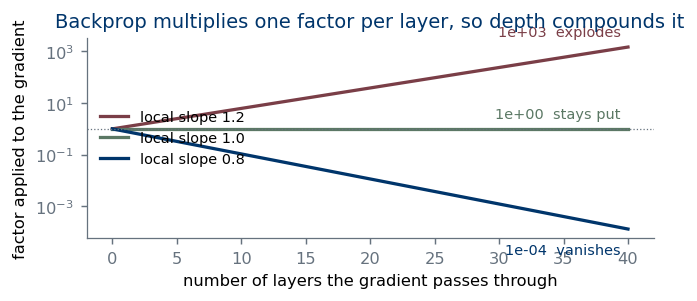

  factors at depth 40: {0.8: 0.000133, 1.0: 1.0, 1.2: 1469.771568}


In [7]:
gradient_products()

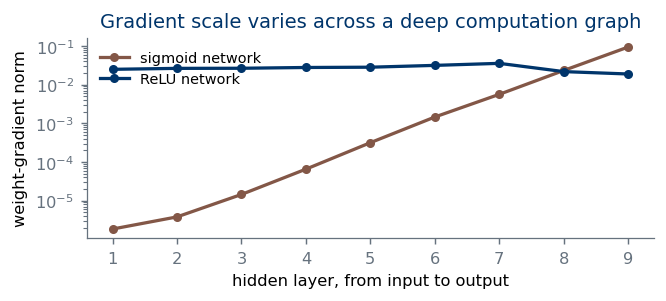

  sigmoid: layer 9 over layer 1 = 5.1e+04; ReLU: 0.76


In [8]:
layer_gradient_norms()

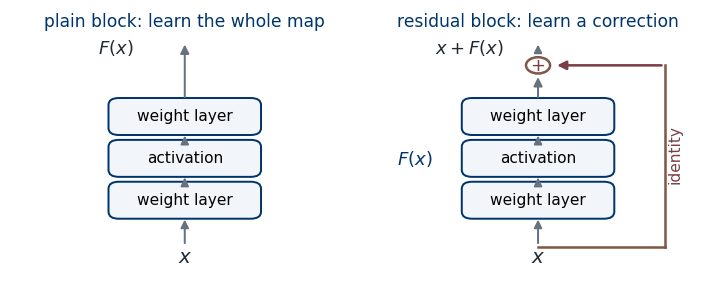

In [9]:
residual_block()

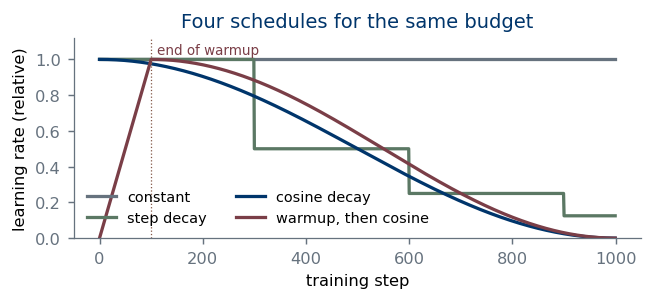

In [10]:
lr_schedules()

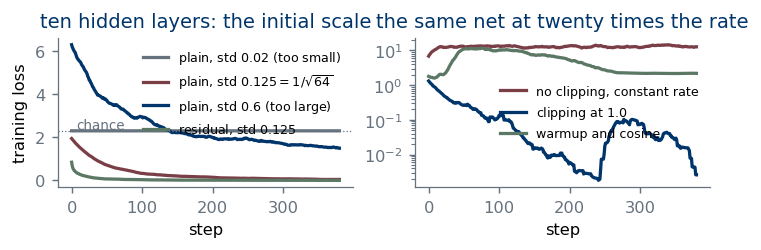

  plain, std $0.02$ (too small)    final smoothed loss 2.302
  plain, std $0.125=1/\sqrt{64}$   final smoothed loss 0.049
  plain, std $0.6$ (too large)     final smoothed loss 1.495
  residual, std $0.125$            final smoothed loss 0.006
  no clipping, constant rate       final smoothed loss 12.736
  clipping at $1.0$                final smoothed loss 0.003
  warmup and cosine                final smoothed loss 2.190


In [11]:
stabilization_comparison()

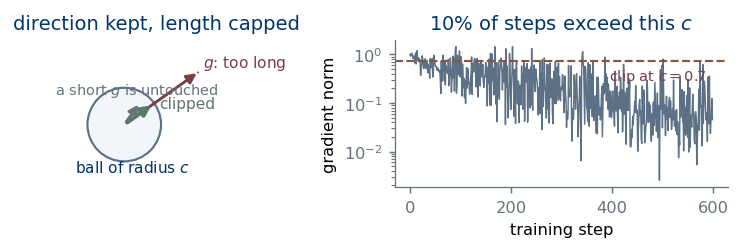

  gradient norms: median 0.18, max 1.45, ratio 7.9x


In [12]:
gradient_clipping()

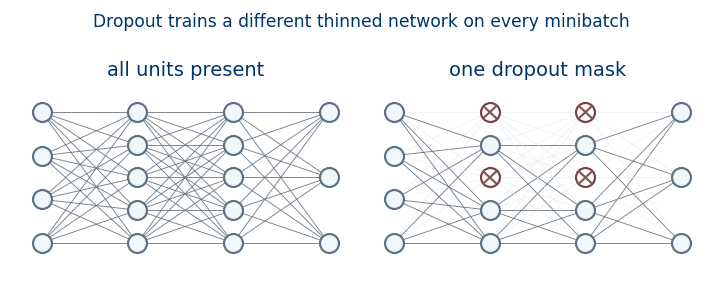

In [13]:
dropout_figure()